In [2]:
# from rfdetr import RFDETRNano
# from rfdetr import RFDETRMedium
from rfdetr import RFDETRLarge
# model = RFDETRNano()
# model = RFDETRMedium()
model = RFDETRLarge(pretrain_weights="./output_large_2/checkpoint_best_total.pth")

Loading pretrain weights


In [3]:
from PIL import Image
import supervision as sv

image = Image.open("./rfdetr_dataset/valid/1478020224197266285.jpg")
detections = model.predict(image)

val_ds = sv.DetectionDataset.from_coco(
    images_directory_path="rfdetr_dataset/valid",
    annotations_path="rfdetr_dataset/valid/_annotations.coco.json"
)

Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().


In [5]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision

targets = []
predictions = []

for path, image, annotations in tqdm(val_ds):
    image = Image.open(path)
    detections = model.predict(image, threshold=0)

    targets.append(annotations)
    predictions.append(detections)

100%|██████████| 2250/2250 [02:14<00:00, 16.75it/s]


In [6]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.478
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.869
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.462
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.436
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ]                 = 0.620
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ]                 = 0.762


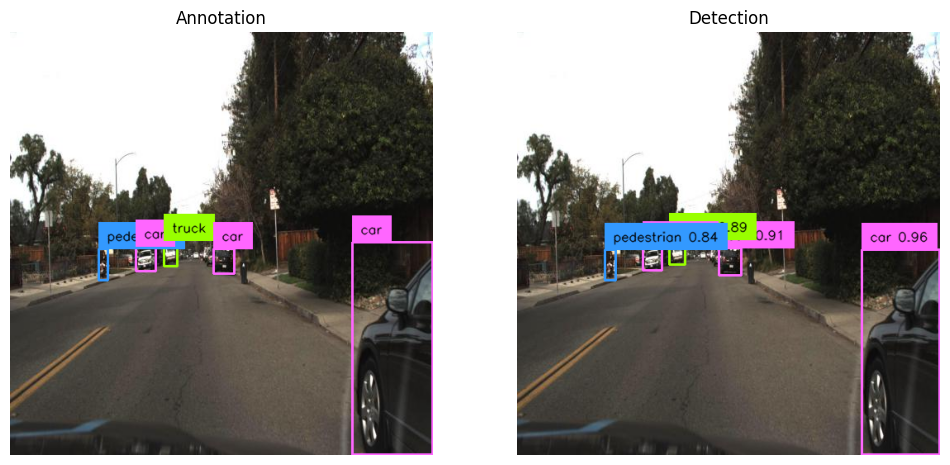

In [10]:
import supervision as sv
from PIL import Image

path, image, annotations = val_ds[110]
image = Image.open(path)

detections = model.predict(image, threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)
color = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

bbox_annotator = sv.BoxAnnotator(color=color,thickness=thickness)
label_annotator = sv.LabelAnnotator(
    color=color, 
    text_color=sv.Color.BLACK,
    text_scale=text_scale)

annotations_labels = [
    f"{val_ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{val_ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])